# Forecasting with Chronos

Example from book `Time Series Forecasting Using Foundation Models`.

In [21]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from chronos import ChronosPipeline

import warnings

warnings.filterwarnings("ignore")

## Zero-shot forecasting with Chronos

In [22]:
df = pd.read_csv("../data/walmart_sales_small.csv", parse_dates=["Date"])
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


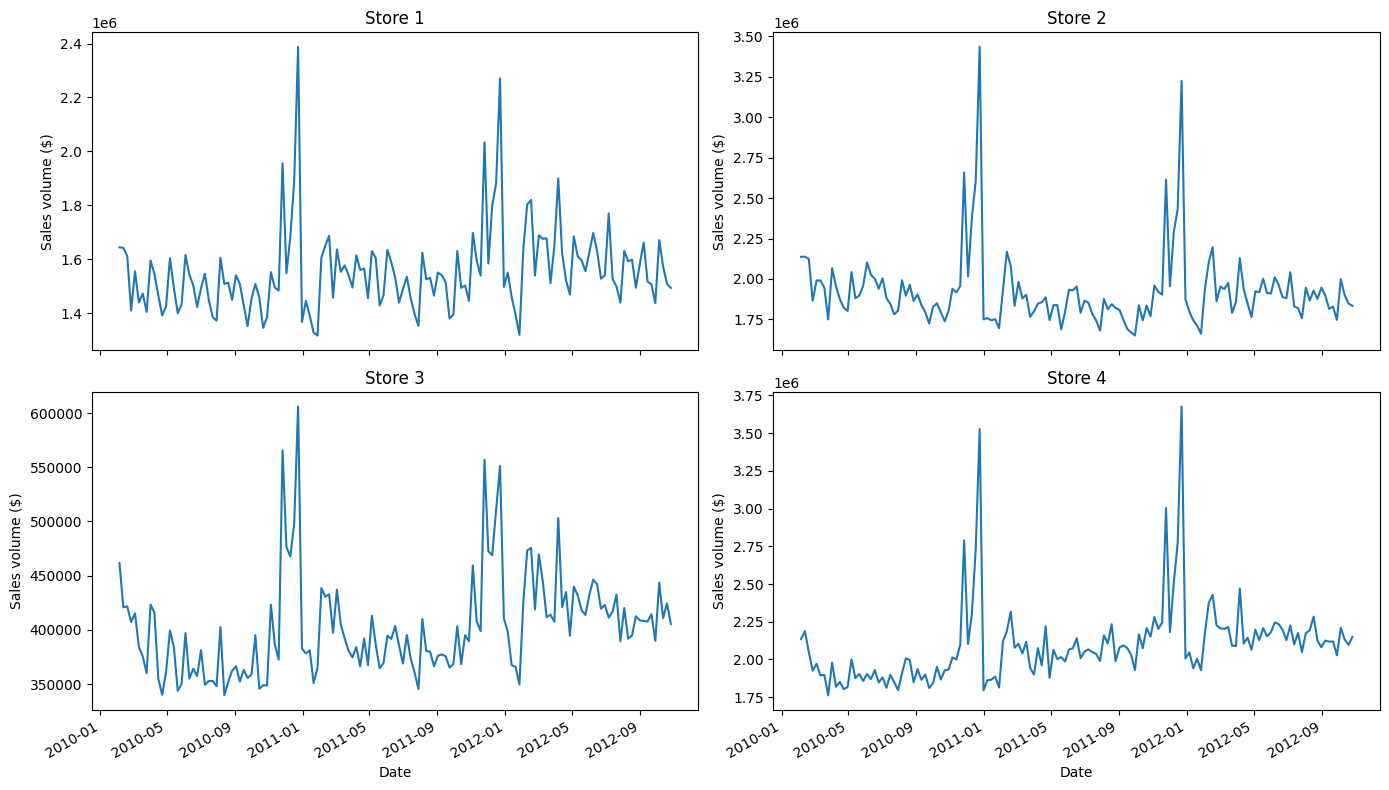

In [23]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(14, 8))

for i, ax in enumerate(axes.flatten()):
    store_id = i + 1
    data = df.query("Store == @store_id")

    ax.plot(data["Date"], data["Weekly_Sales"])
    ax.set_title(f"Store {store_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Sales volume ($)")

fig.autofmt_xdate()
plt.tight_layout()

In [24]:
context = [
    torch.tensor(df.query("Store == @i")["Weekly_Sales"].to_numpy())
    for i in range(1, 5)
]

In [25]:
pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-small",
    device_map="cpu",  # use "cpu" for CPU inference, "mps" for Apple Silicon, "cuda" for GPU supporting CUDA
    torch_dtype=torch.bfloat16,
)

predictions = pipeline.predict(
    context,  # pass context as positional argument (not keyword arg)
    prediction_length=8,
    num_samples=20,
)

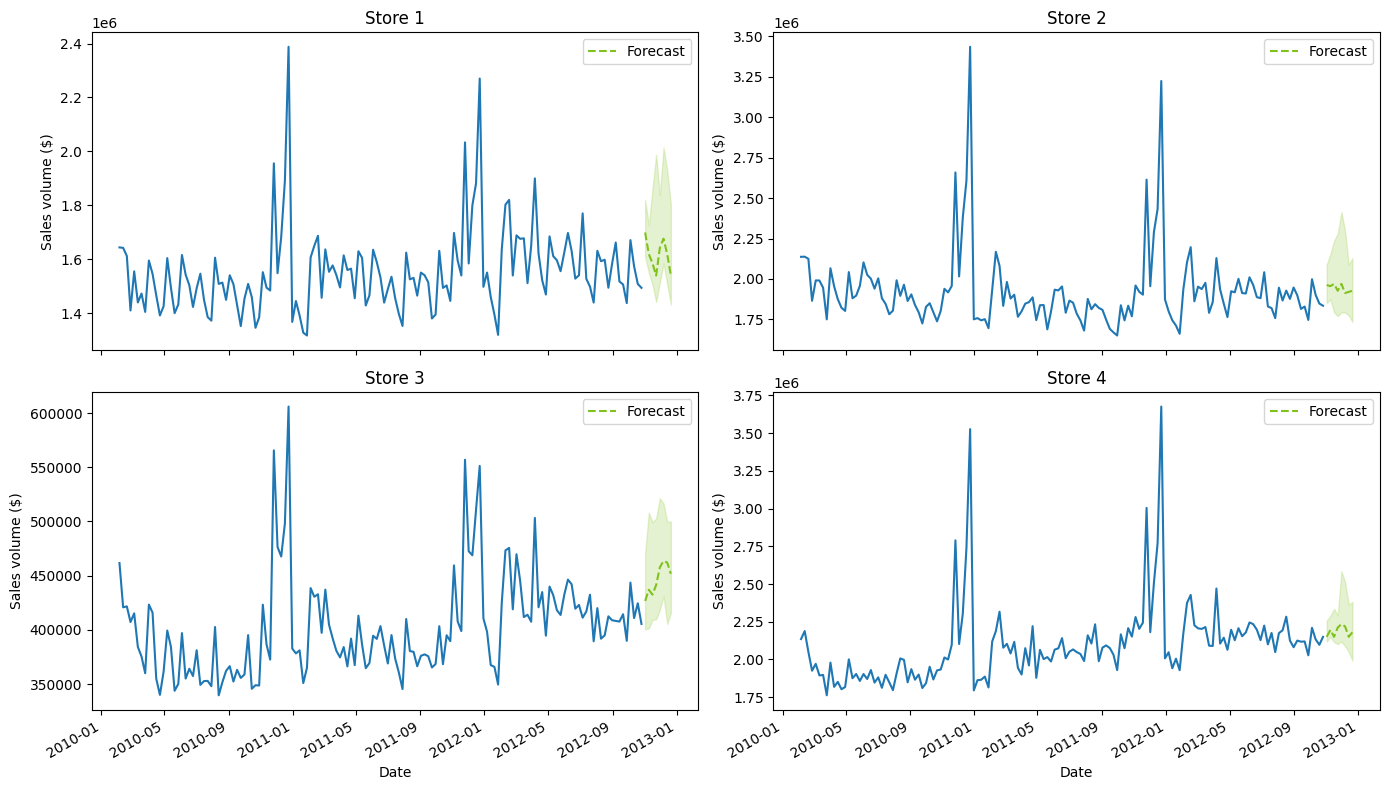

In [26]:
start_date = pd.to_datetime("2012-10-26")
forecast_dates = [start_date + pd.DateOffset(weeks=i) for i in range(1, 9)]

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(14, 8))

for i, ax in enumerate(axes.flatten()):
    store_id = i + 1
    data = df.query("Store == @store_id")
    low, median, high = np.quantile(predictions[i].numpy(), [0.1, 0.5, 0.9], axis=0)

    ax.plot(data["Date"], data["Weekly_Sales"])
    ax.plot(forecast_dates, median, ls="--", color="#80c21d", label="Forecast")
    ax.fill_between(forecast_dates, low, high, color="#80c21d", alpha=0.2)

    ax.set_title(f"Store {store_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Sales volume ($)")
    ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

## Cross-validation with Chronos

In [27]:
def cross_validation_chronos(df, h, n_windows, target_col):

    lows = []
    medians = []
    highs = []

    for i in range(n_windows, 0, -1):
        context = torch.tensor(df[target_col][: -(h * i)])

        predictions = pipeline.predict(
            context,
            prediction_length=h,
            num_samples=20,
        )

        low, median, high = np.quantile(predictions[0].numpy(), [0.1, 0.5, 0.9], axis=0)

        lows.extend(low)
        medians.extend(median)
        highs.extend(high)

    return lows, medians, highs

In [28]:
df = df.query("Store == 1")

lows, medians, highs = cross_validation_chronos(
    df, h=8, n_windows=4, target_col="Weekly_Sales"
)

In [29]:
test_df = df[["Store", "Date", "Weekly_Sales"]][-32:]

test_df["low"] = lows
test_df["median"] = medians
test_df["high"] = highs

test_df.head()

,Store,Date,Weekly_Sales,low,median,high
111,1,2012-03-23,1511068.07,1463471.000,1588263.000,1726668.875
112,1,2012-03-30,1649604.63,1449857.250,1582590.625,1701710.500
113,1,2012-04-06,1899676.88,1538346.250,1633642.000,1731206.750
114,1,2012-04-13,1621031.70,1542884.125,1639314.500,1726668.875
115,1,2012-04-20,1521577.87,1473681.125,1559901.250,1720996.500


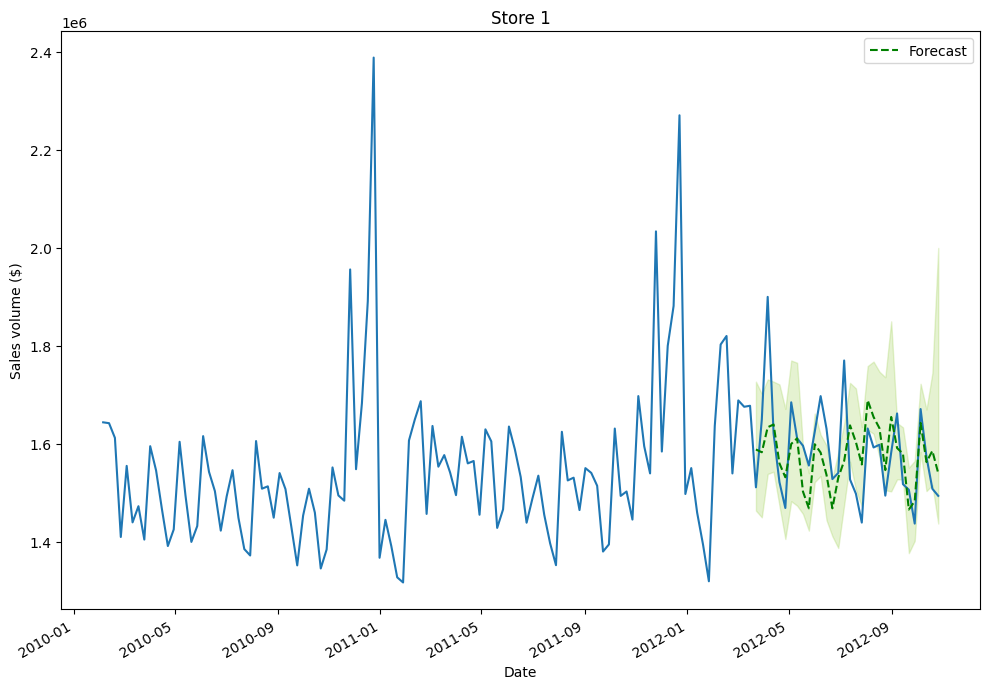

In [30]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(df["Date"], df["Weekly_Sales"])
ax.plot(test_df["Date"], test_df["median"], ls="--", color="green", label="Forecast")
ax.fill_between(
    test_df["Date"], test_df["low"], test_df["high"], color="#80c21d", alpha=0.2
)

ax.set_title(f"Store 1")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume ($)")
ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

In [31]:
from utilsforecast.losses import mae, smape
from utilsforecast.evaluation import evaluate

evaluation = evaluate(
    test_df,
    metrics=[mae, smape],
    models=["median"],
    target_col="Weekly_Sales",
    id_col="Store",
)

evaluation

,Store,metric,median
0,1,mae,71839.039531
1,1,smape,0.022512


## Anomaly detection

In [34]:
df = pd.read_csv("../data/nyc_taxi_anomaly_daily.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value,is_anomaly
0,2014-07-01,745967,0
1,2014-07-02,733640,0
2,2014-07-03,710142,0
3,2014-07-04,552565,0
4,2014-07-05,555470,0


In [35]:
def anomaly_detection_chronos(df, h, n_windows, value_col, confidence=0.99):

    lows = []
    medians = []
    highs = []

    low_conf = (1 - confidence) / 2

    for i in range(n_windows, 0, -1):
        context = torch.tensor(df[value_col][: -(h * i)])

        predictions = pipeline.predict(
            context,
            prediction_length=h,
            num_samples=20,
            limit_prediction_length=False,
        )

        low, median, high = np.quantile(
            predictions[0].numpy(), [low_conf, 0.5, 1 - low_conf], axis=0
        )

        lows.extend(low)
        medians.extend(median)
        highs.extend(high)

    df_test = df[-(n_windows * h) :]

    df_test["low"] = lows
    df_test["median"] = medians
    df_test["high"] = highs

    df_test["anomaly"] = (
        (df_test[value_col] < df_test["low"]) | (df_test[value_col] > df_test["high"])
    ).astype(int)

    return df_test

In [37]:
anomaly_df = anomaly_detection_chronos(
    df, h=23, n_windows=8, value_col="value", confidence=0.99
)
anomaly_df.head()

,timestamp,value,is_anomaly,low,median,high,anomaly
31,2014-08-01,769160,0,663574.0000,765094.125,806804.8750,0
32,2014-08-02,781616,0,583397.4375,770370.625,837461.3750,0
33,2014-08-03,699449,0,625635.8750,754541.000,828412.1875,0
34,2014-08-04,662215,0,552767.2500,738711.500,821130.6250,0
35,2014-08-05,710728,0,557278.6875,725520.250,820629.3125,0


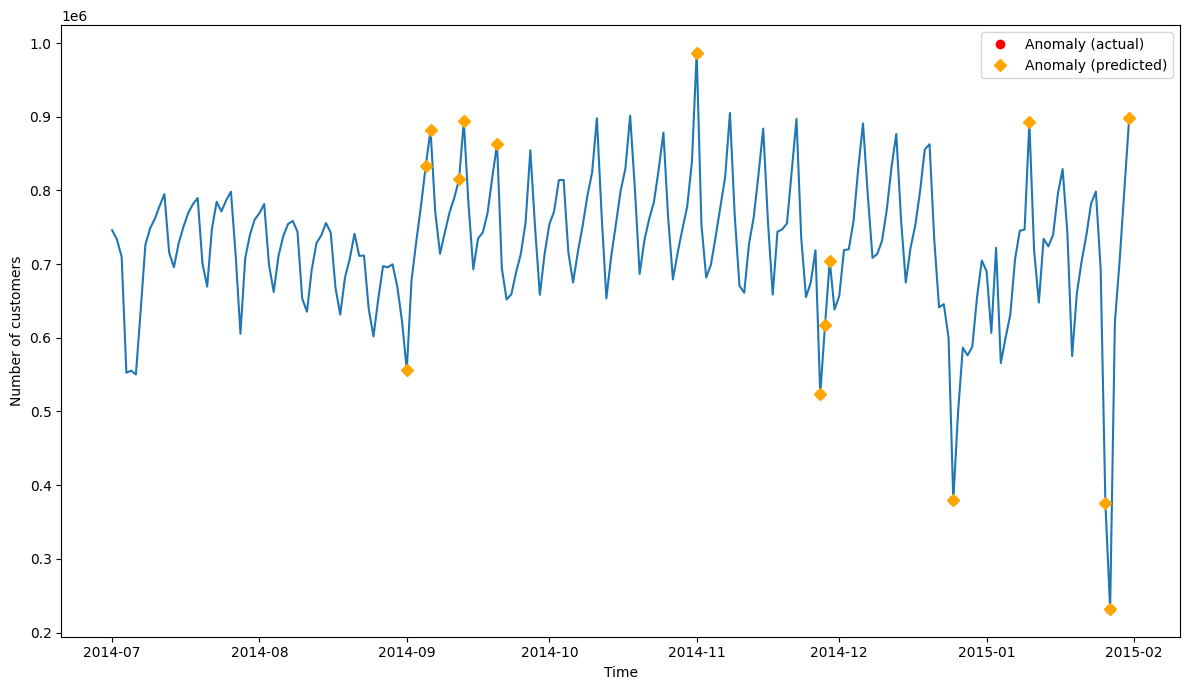

In [38]:
actual_anomaly_df = df.loc[df["is_anomaly"] == 1]
pred_anomaly_df = anomaly_df.loc[anomaly_df["anomaly"] == 1]

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(df["timestamp"], df["value"])
ax.plot(
    actual_anomaly_df["timestamp"],
    actual_anomaly_df["value"],
    "o",
    color="red",
    label="Anomaly (actual)",
)
ax.plot(
    pred_anomaly_df["timestamp"],
    pred_anomaly_df["value"],
    "D",
    color="orange",
    label="Anomaly (predicted)",
)
ax.set_xlabel("Time")
ax.set_ylabel("Number of customers")
ax.legend(loc="best")

plt.tight_layout()

In [39]:
def evaluate_anomaly_detection(df, preds_col, actual_col):
    tp = ((df[preds_col] == 1) & (df[actual_col] == 1)).sum()
    tn = ((df[preds_col] == 0) & (df[actual_col] == 0)).sum()
    fp = ((df[preds_col] == 1) & (df[actual_col] == 0)).sum()
    fn = ((df[preds_col] == 0) & (df[actual_col] == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0
    f1_score = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) != 0
        else 0
    )

    return precision, recall, f1_score

In [40]:
precision, recall, f1_score = evaluate_anomaly_detection(
    anomaly_df[-182:], "anomaly", "is_anomaly"
)

print(f"Precision: {round(precision,2)}")
print(f"Recall: {round(recall,2)}")
print(f"F1-Score: {round(f1_score,2)}")

Precision: 0.27
Recall: 1.0
F1-Score: 0.42
